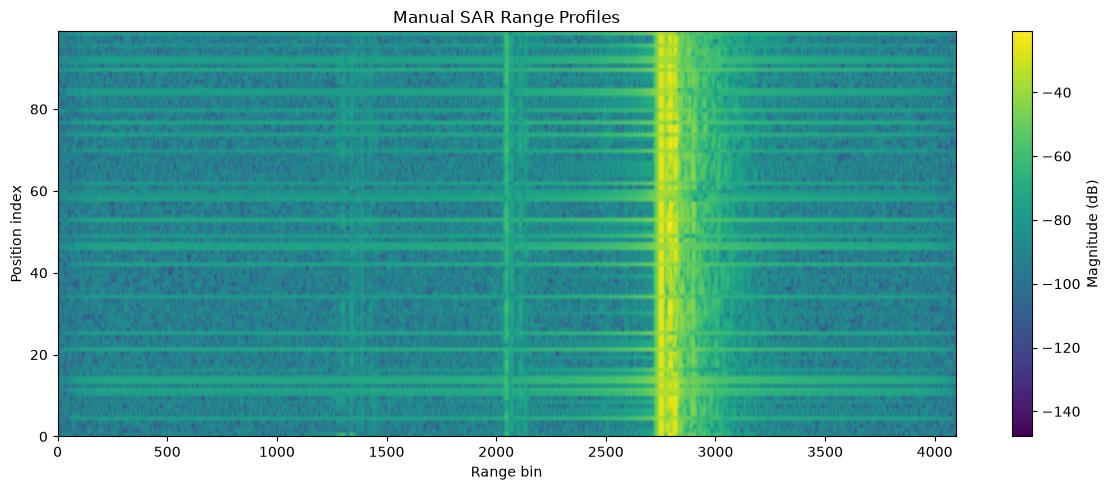

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rp = pd.read_csv("/Users/levifarinas/Documents/XBand-Radar/manual_sar_20261008_101323_782517.csv")

real = rp.filter(regex=r"^bin_\d+_real$").to_numpy()
imag = rp.filter(regex=r"^bin_\d+_imag$").to_numpy()
profiles = real + 1j * imag

db = 20 * np.log10(np.maximum(np.abs(profiles), 1e-12))

plt.figure(figsize=(12, 5))
plt.imshow(db, aspect="auto", origin="lower", cmap="viridis", extent=[0, db.shape[1] - 1, 0, db.shape[0] - 1])
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Range bin")
plt.ylabel("Position index")
plt.title("Manual SAR Range Profiles")
plt.tight_layout()
plt.show()

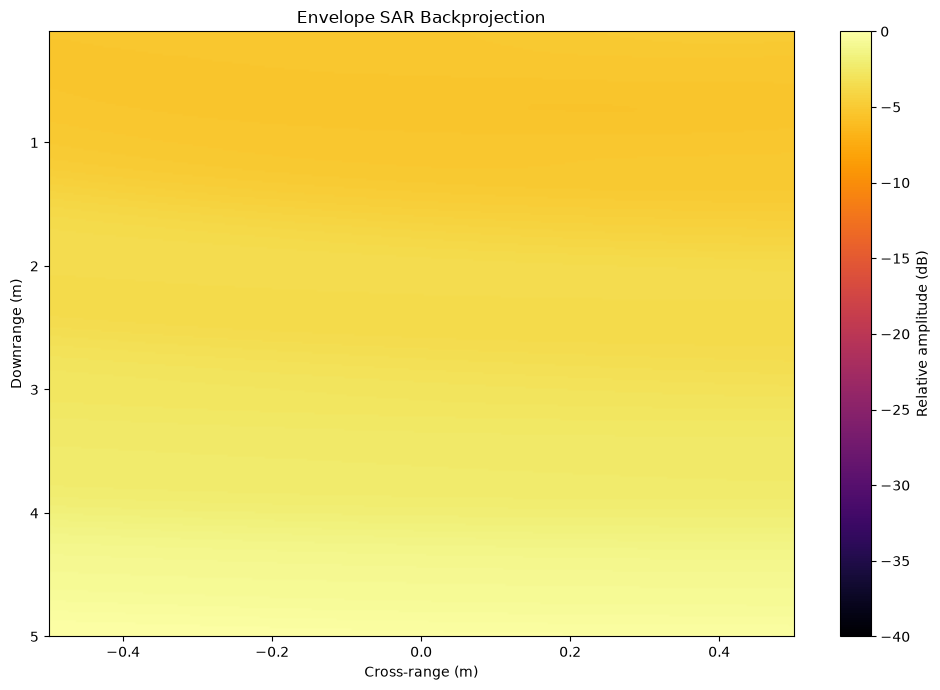

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from Imaging import backproject

path = "/Users/levifarinas/Documents/XBand-Radar/manual_sar_20261008_102211_953480.csv"

df = pd.read_csv(path)
real = df.filter(regex=r"^bin_\d+_real$").to_numpy()
imag = df.filter(regex=r"^bin_\d+_imag$").to_numpy()
rp = real + 1j * imag

rp = np.abs(rp).astype(np.complex128)

dx = 0.005
positions = np.zeros((len(rp), 3))
positions[:, 0] = df["position_index"].to_numpy() * dx

fs = 600_000
bandwidth = 500e6
ramp_time = 1.2e-3
fft_size = rp.shape[1]
dr = (fs / fft_size) * 299792458 / (2 * bandwidth / ramp_time)

img, x, y, _ = backproject(
    positions=positions,
    range_profiles=rp,
    dr=dr,
    crossrange=(-0.5, 0.5),
    downrange=(0.1, 5.0),
    resolution=(300, 300),
    fstart=0,
    fstop=bandwidth,
    phase_sign=0,
    flip_lr=False,
    flip_ud=False,
    transpose_output=False,
    output_db=True
)

plt.figure(figsize=(10, 7))
plt.imshow(
    img,
    extent=[x.min(), x.max(), y.max(), y.min()],
    aspect="auto",
    cmap="inferno",
    vmin=-40,
    vmax=0
)
plt.xlabel("Cross-range (m)")
plt.ylabel("Downrange (m)")
plt.title("Envelope SAR Backprojection")
plt.colorbar(label="Relative amplitude (dB)")
plt.tight_layout()
plt.show()